# Sesión 11 · Notebook de clase · Relaciones entre variables: dispersión y correlación

**Fundamentos de Ciencia de Datos e IA (CDIAG1003)** · Semana 6 · Unidad 3: tema 3.3 (dos variables a la vez) y tema 3.4 (correlación: Pearson, Spearman, matriz de correlación, mapa de calor; correlación no es causalidad).

En la sesión 10 describimos **una variable por separado** (centro, dispersión, forma, atípicos). Casi todas las preguntas de negocio relacionan **dos**: ¿los ciclos más largos dan camarones más pesados?, ¿las piscinas más grandes cosechan más?, ¿vender más unidades deja más margen? Hoy: cómo **ver** una relación (diagrama de dispersión), cómo **medirla** con un número (correlación) y qué **no** dice ese número.

Datos, en la carpeta `datos/`:

| Archivo | Qué es |
| :-- | :-- |
| `cosechas.csv` | 480 ciclos de cosecha de camarón (2024–2025): zona, laboratorio, días, hectáreas, densidad, supervivencia, peso, cosecha, alimento, precio (sesión 10) |
| `ventas_completo.csv` | las 260 ventas de enero a abril (sesión 9) |

**Cómo trabajar con este notebook**
- Ejecute las celdas en orden. En los ejercicios **Su turno**, reemplace los `...`; la celda `assert` siguiente comprueba el resultado.
- Todo gráfico lleva título y etiquetas con unidad en los dos ejes (regla de la sesión 10).
- Las salidas de la versión resuelta están en pandas 3 (texto con tipo `str`; en pandas 2 aparece `object`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

c = pd.read_csv("datos/cosechas.csv", parse_dates=["fecha_siembra"])
v = pd.read_csv("datos/ventas_completo.csv", parse_dates=["fecha"])
print("cosechas:", c.shape, "| ventas:", v.shape)
c.head(3)

cosechas: (480, 13) | ventas: (260, 13)


,ciclo,piscina,zona,laboratorio,fecha_siembra,dias,hectareas,densidad,supervivencia,peso_g,cosecha_kg,alimento_kg,precio_kg
0,C-0001,P323,Guayas,Lab Costa,2024-01-05,118,6.8,13,69.8,25.4,15673,25822,5.49
1,C-0002,P170,El Oro,Lab Norte,2024-01-06,103,10.9,13,63.0,21.0,18747,28098,5.98
2,C-0003,P327,Guayas,Lab Sur,2024-01-11,113,5.4,18,68.5,20.5,13649,19611,4.82


## 1. Dos variables numéricas: el diagrama de dispersión

El **diagrama de dispersión** (*scatter plot*) pone una variable en cada eje y **un punto por fila**. Es el primer gráfico que se hace para dos numéricas, siempre antes de calcular cualquier número. Se lee con cuatro preguntas:

| Pregunta | Qué mirar | Ejemplo |
| :-- | :-- | :-- |
| **Dirección** | ¿cuando x sube, y sube (positiva) o baja (negativa)? | más días de cultivo → más peso |
| **Forma** | ¿los puntos siguen una **recta**, una curva, o nada? | una recta: relación lineal |
| **Fuerza** | ¿están cerca de la forma o muy dispersos? | una nube ancha: relación débil |
| **Puntos raros** | ¿hay puntos lejos de todos? | una piscina de 52 ha |

`ax.scatter(x, y)` dibuja; `alpha` (transparencia) deja ver dónde se amontonan los puntos.

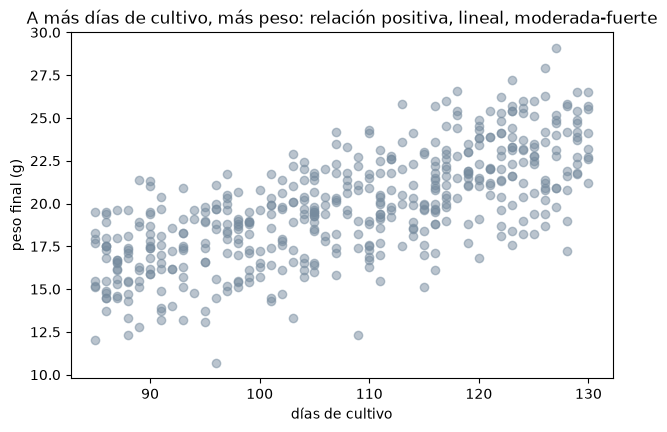

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(c["dias"], c["peso_g"], alpha=0.5, color="#768B9E")
ax.set_xlabel("días de cultivo")
ax.set_ylabel("peso final (g)")
ax.set_title("A más días de cultivo, más peso: relación positiva, lineal, moderada-fuerte")
plt.show()

Lectura: la nube **sube** de izquierda a derecha (positiva), sigue una **recta** (lineal) y los puntos están razonablemente cerca de ella (fuerte). No hay puntos raros.

### Su turno 1.1 · 3 min
Dibuje la dispersión de `hectareas` (eje x) frente a `cosecha_kg` (eje y), con etiquetas con unidad y título. Responda las cuatro preguntas en el título o en un comentario. ¿Ve algún punto raro?

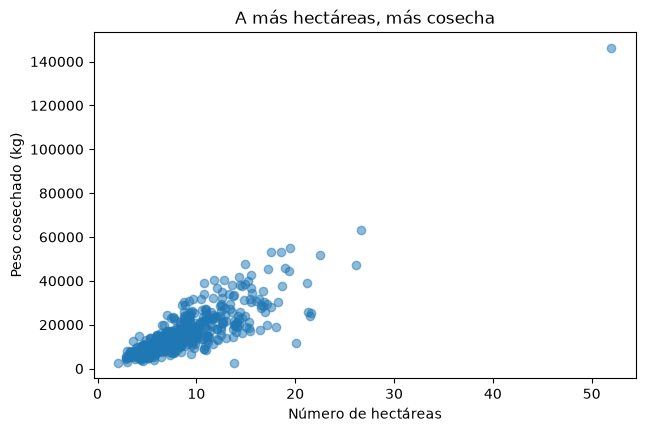

In [15]:
# TODO: reemplace los ... por su código
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(c["hectareas"], c["cosecha_kg"], alpha=0.5)
ax.set_xlabel("Número de hectáreas")
ax.set_ylabel("Peso cosechado (kg)")
ax.set_title("A más hectáreas, más cosecha")
plt.show()

In [16]:
assert len(ax.collections) == 1 and len(ax.collections[0].get_offsets()) == 480, "un ax.scatter con los 480 ciclos"
assert ax.get_xlabel() != "" and ax.get_ylabel() != "" and ax.get_title() != "", "faltan etiquetas o título"
print("Correcto. La piscina de 52 ha (arriba a la derecha) está lejos de todas: un punto raro que tira de la recta.")

Correcto. La piscina de 52 ha (arriba a la derecha) está lejos de todas: un punto raro que tira de la recta.


## 2. Medir la relación: el coeficiente de correlación de Pearson

El **coeficiente de correlación de Pearson** (`r`) resume la dispersión en un número entre **−1 y 1**:

- el **signo** dice la dirección (positiva o negativa);
- el **valor absoluto** dice la fuerza de la relación **lineal**: 1 o −1 es una recta perfecta; 0 es «ninguna relación lineal».

Se calcula a partir de la **covarianza** (cuánto se mueven juntas las dos variables respecto de sus medias) dividida entre las dos desviaciones estándar: por eso **no tiene unidades** y no cambia si se pasa de gramos a kilos. En pandas: `x.corr(y)`.

| \|r\| | Lectura habitual (guía, no ley) |
| :-- | :-- |
| menos de 0,3 | débil o nula |
| 0,3 a 0,7 | moderada |
| más de 0,7 | fuerte |

Lo que `r` **no** mide: relaciones no lineales (una curva en U puede dar `r ≈ 0`), y es sensible a los atípicos (un punto lejano cambia mucho el valor). Por eso el gráfico va primero.

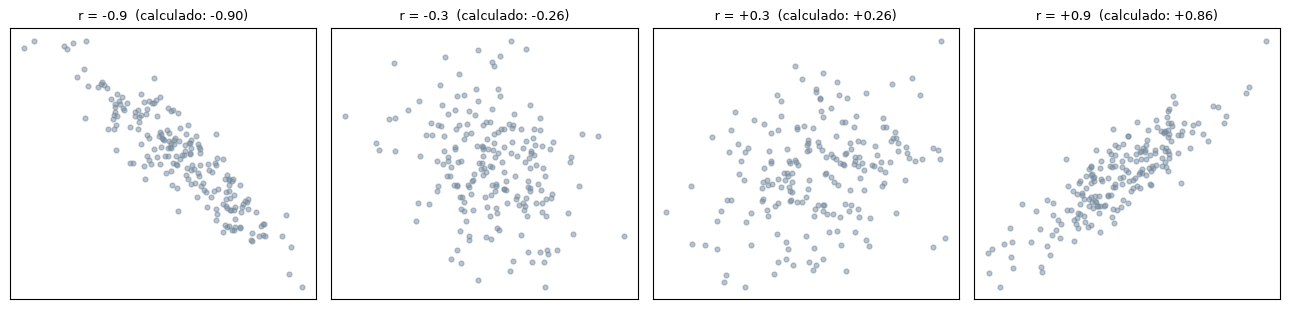

In [ ]:
# El mismo r, visto: cuatro nubes simuladas con correlación conocida
rng = np.random.default_rng(2605) # Genera pares ordenados (x, y)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2)) # zip genera pares (ax, r) para cada ax y r
for ax, r in zip(axes, [-0.9, -0.3, 0.3, 0.9]):
    xy = rng.multivariate_normal([0, 0], [[1, r], [r, 1]], size=200)
    ax.scatter(xy[:, 0], xy[:, 1], alpha=0.5, s=12, color="#768B9E")
    ax.set_title(f"r = {r:+.1f}  (calculado: {np.corrcoef(xy[:, 0], xy[:, 1])[0, 1]:+.2f})", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plt.show()

In [18]:
r = c["dias"].corr(c["peso_g"])
print("Pearson dias-peso_g:", round(r, 3), "-> positiva y fuerte (confirma el gráfico de la sección 1)")
print("covarianza:", round(c["dias"].cov(c["peso_g"]), 2), "(tiene unidades: días x gramos; el signo es lo único que se lee)")

Pearson dias-peso_g: 0.702 -> positiva y fuerte (confirma el gráfico de la sección 1)
covarianza: 29.67 (tiene unidades: días x gramos; el signo es lo único que se lee)


### Su turno 2.1 · 3 min
Calcule en `r_ha_cos` la correlación de Pearson entre `hectareas` y `cosecha_kg` (la dispersión de «Su turno 1.1») y en `r_den_sup` la de `densidad` con `supervivencia`. Antes de ejecutar, prediga el signo y la fuerza de cada una.

In [36]:
# TODO: reemplace los ... por su código
r_ha_cos = c["hectareas"].corr(c["cosecha_kg"])
r_den_sup = c["densidad"].corr(c["supervivencia"])
print("hectáreas-cosecha:", round(r_ha_cos, 2), "| densidad-supervivencia:", round(r_den_sup, 2))

hectáreas-cosecha: 0.84 | densidad-supervivencia: -0.03


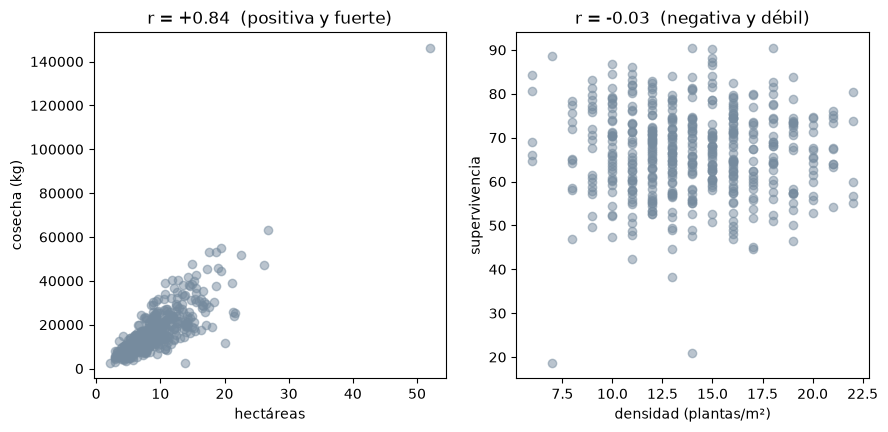

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].scatter(c["hectareas"], c["cosecha_kg"], alpha=0.5, color="#768B9E")
ax[0].set_xlabel("hectáreas")
ax[0].set_ylabel("cosecha (kg)")
ax[0].set_title(f"r = {r_ha_cos:+.2f}  (positiva y fuerte)")
ax[1].scatter(c["densidad"], c["supervivencia"], alpha=0.5, color="#768B9E")
ax[1].set_xlabel("densidad (plantas/m²)")
ax[1].set_ylabel("supervivencia")
ax[1].set_title(f"r = {r_den_sup:+.2f}  (negativa y débil)")
plt.show()

In [37]:
assert np.isclose(round(r_ha_cos, 2), 0.84) and np.isclose(round(r_den_sup, 2), -0.03), "use .corr() entre las dos columnas"
print("Correcto: hectáreas-cosecha fuerte y positiva; densidad-supervivencia prácticamente nula (en estos datos sembrar más denso no baja la supervivencia).")

Correcto: hectáreas-cosecha fuerte y positiva; densidad-supervivencia prácticamente nula (en estos datos sembrar más denso no baja la supervivencia).


## 3. Spearman: la correlación de los rangos

La correlación de **Spearman** (`method="spearman"`) hace lo mismo que Pearson pero sobre los **rangos** (el puesto de cada valor: 1.º, 2.º, …) en vez de sobre los valores. Mide si la relación es **monótona** (siempre sube o siempre baja), sea recta o curva. Conviene cuando:

- la relación es claramente **no lineal** pero monótona (una curva que siempre sube);
- hay **atípicos** que deforman a Pearson (en los rangos, 146 286 kg es solo «el primero»);
- alguna variable es **ordinal** (una escala de 1 a 5, tallas, niveles).

Si Pearson y Spearman se parecen, la relación es aproximadamente lineal y sin atípicos influyentes. Si Spearman es claramente mayor, hay una relación monótona que la recta no captura, o un atípico que tira de Pearson.

Pearson : 0.895
Spearman: 1.0


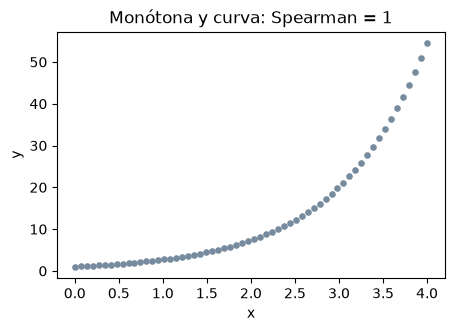

In [41]:
# Una relación monótona pero no lineal: Pearson la subestima, Spearman la ve completa
x = np.linspace(0, 4, 60)
y = np.exp(x)                                  # siempre sube, pero no en línea recta
par = pd.DataFrame({"x": x, "y": y})
print("Pearson :", round(par["x"].corr(par["y"]), 3))
print("Spearman:", round(par["x"].corr(par["y"], method="spearman"), 3))
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.scatter(x, y, s=14, color="#768B9E"); ax.set_title("Monótona y curva: Spearman = 1"); ax.set_xlabel("x"); ax.set_ylabel("y")
plt.show()

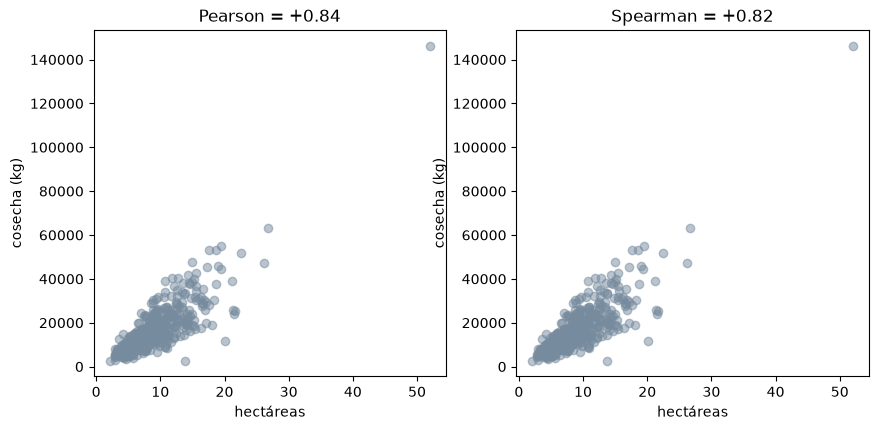

Pearson : 0.84
Spearman: 0.816  <- parecidas: lineal, el atípico no cambia la conclusión


In [44]:
# En cosechas: hectáreas-cosecha con y sin el efecto de la piscina de 52 ha
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].scatter(c["hectareas"], c["cosecha_kg"], alpha=0.5, color="#768B9E")
ax[0].set_xlabel("hectáreas")
ax[0].set_ylabel("cosecha (kg)")
ax[0].set_title(f"Pearson = {c['hectareas'].corr(c['cosecha_kg']):+.2f}")
ax[1].scatter(c["hectareas"], c["cosecha_kg"], alpha=0.5, color="#768B9E")
ax[1].set_xlabel("hectáreas")
ax[1].set_ylabel("cosecha (kg)")
ax[1].set_title(f"Spearman = {c['hectareas'].corr(c['cosecha_kg'], method='spearman'):+.2f}")
plt.show()

print("Pearson :", round(c["hectareas"].corr(c["cosecha_kg"]), 3))
print("Spearman:", round(c["hectareas"].corr(c["cosecha_kg"], method="spearman"), 3), " <- parecidas: lineal, el atípico no cambia la conclusión")

### Su turno 3.1 · 3 min
Para `peso_g` y `precio_kg` (camarón más grande, mejor precio por kilo): calcule Pearson en `r_p` y Spearman en `r_s`. ¿Es una relación fuerte, moderada o débil? ¿Lineal?

In [49]:
# TODO: reemplace los ... por su código
r_p = c["peso_g"].corr(c["precio_kg"])
r_s = c["peso_g"].corr(c["precio_kg"], method="spearman")
print("Pearson:", round(r_p, 2), "| Spearman:", round(r_s, 2))

Pearson: 0.39 | Spearman: 0.33


In [50]:
assert np.isclose(round(r_p, 2), 0.39) and np.isclose(round(r_s, 2), 0.33), "Pearson con .corr(); Spearman con method='spearman'"
print("Correcto: positiva y moderada; las dos se parecen, así que es aproximadamente lineal. El peso explica parte del precio, no todo.")

Correcto: positiva y moderada; las dos se parecen, así que es aproximadamente lineal. El peso explica parte del precio, no todo.


## 4. Todas las parejas a la vez: la matriz de correlación y el mapa de calor

`df.corr()` calcula `r` para **todas las parejas** de columnas numéricas: una tabla cuadrada y simétrica con 1 en la diagonal. Solo se le pasan las columnas que tiene sentido correlacionar (no identificadores ni códigos). Un **mapa de calor** (*heatmap*) la pinta: color por valor, de −1 (azul) a 1 (rojo), con el número encima. Con matplotlib son unas pocas líneas (`imshow` + barra de color + texto); seaborn lo hace en una (`sns.heatmap`).

Cómo leerla: buscar las celdas **lejos de 0** (fuertes), comprobar su signo, y preguntarse si una pareja fuerte es una **relación real** o dos columnas que miden casi lo mismo (**redundantes**).

In [51]:
numericas = ["dias", "hectareas", "densidad", "supervivencia", "peso_g", "cosecha_kg", "alimento_kg", "precio_kg"]
m = c[numericas].corr().round(2)
m

,dias,hectareas,densidad,supervivencia,peso_g,cosecha_kg,alimento_kg,precio_kg
dias,1.00,0.07,-0.09,0.05,0.70,0.20,0.20,0.28
hectareas,0.07,1.00,0.05,-0.03,0.08,0.84,0.82,0.01
densidad,-0.09,0.05,1.00,-0.03,-0.11,0.37,0.37,-0.06
supervivencia,0.05,-0.03,-0.03,1.00,0.02,0.22,0.19,0.03
peso_g,0.70,0.08,-0.11,0.02,1.00,0.26,0.26,0.39
cosecha_kg,0.20,0.84,0.37,0.22,0.26,1.00,0.98,0.10
alimento_kg,0.20,0.82,0.37,0.19,0.26,0.98,1.00,0.10
precio_kg,0.28,0.01,-0.06,0.03,0.39,0.10,0.10,1.00


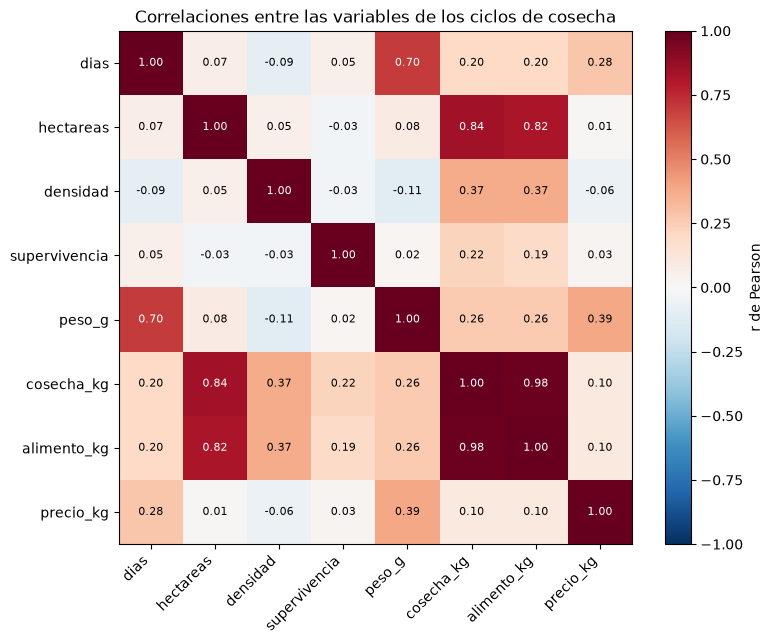

In [ ]:
def mapa_calor(m, ax, titulo):
    # Hacer la tabla gráfica mapeada con colores
    im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1) # Crea una tabla con valores de m mapeado con colores
    ax.set_xticks(range(len(m)), labels=m.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(m)), labels=m.index)

    # Mostrar cada valor dentro del mapa (Cada correlación)
    for i in range(len(m)):    
        for j in range(len(m)):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(m.iloc[i, j]) > 0.6 else "black")
    ax.figure.colorbar(im, ax=ax, label="r de Pearson")
    ax.set_title(titulo)

fig, ax = plt.subplots(figsize=(8, 6.5))
mapa_calor(m, ax, "Correlaciones entre las variables de los ciclos de cosecha")
fig.tight_layout()
plt.show()

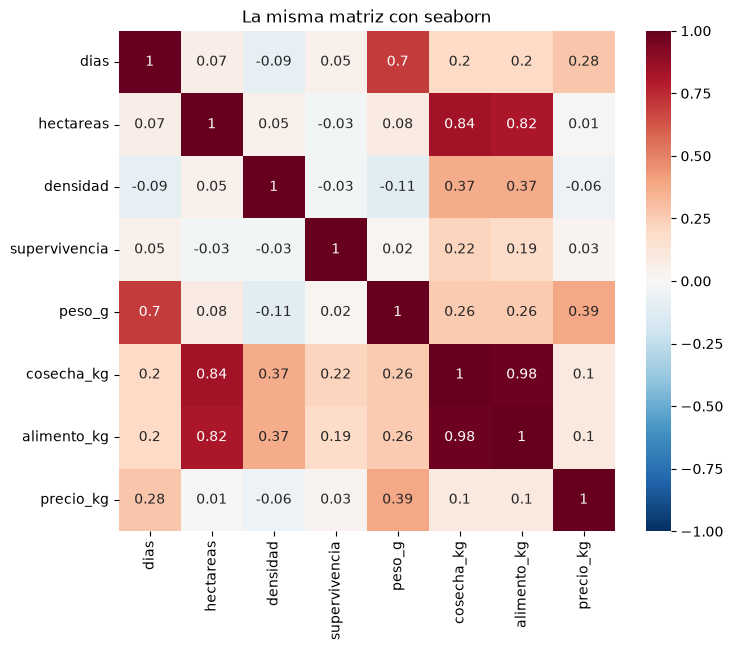

In [53]:
# El atajo de seaborn (viene con Anaconda): la misma matriz en una línea
import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(m, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("La misma matriz con seaborn")
plt.show()

Lectura de la matriz (las parejas con |r| > 0,7):

- `cosecha_kg`–`alimento_kg` (0.98): **redundantes**. El alimento se dosifica según la biomasa: a más cosecha, más alimento. Las dos columnas cuentan casi lo mismo; en un análisis se usa una de ellas (o su cociente, el factor de conversión).
- `hectareas`–`cosecha_kg` (0.84): una piscina más grande cosecha más kilos. Es una relación de **tamaño**, no de manejo: por eso en la sección 6 se compara **por hectárea**.
- `dias`–`peso_g` (0.7): más días de cultivo, camarón más pesado. Esta sí es una relación de manejo.

Casi todo lo demás queda por debajo de 0,4: supervivencia y precio apenas se relacionan linealmente con las otras.

### Su turno 4.1 · 4 min
Construya la matriz de correlación `m_v` de las ventas (`v`) con las columnas `cantidad`, `precio_unitario`, `costo_unitario`, `ingreso` y `margen`, redondeada a 2 decimales, y dibújela como mapa de calor (con la función `mapa_calor` o con seaborn). Después obtenga en `par_max` la **pareja** con mayor correlación fuera de la diagonal (el código de las dos últimas líneas ya está escrito: léalo).

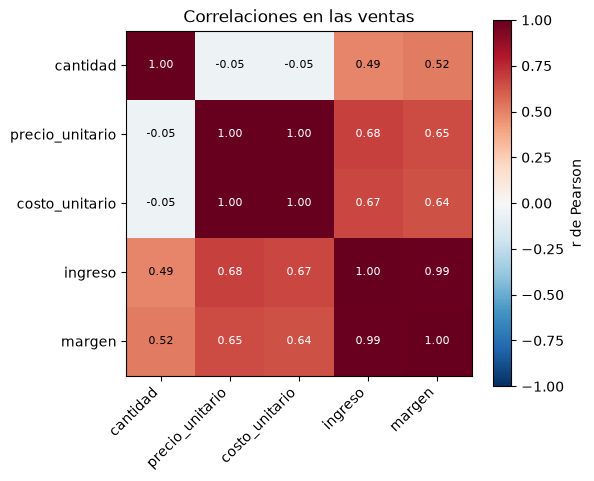

('precio_unitario', 'costo_unitario') 1.0


In [ ]:
# TODO: reemplace los ... por su código
columnas_v = ["cantidad", "precio_unitario", "costo_unitario", "ingreso", "margen"]
m_v = v[columnas_v].corr().round(2)
fig, ax = plt.subplots(figsize=(6, 5))
mapa_calor(m_v, ax, "Correlaciones en las ventas")
fig.tight_layout()
plt.show()
sin_diagonal = m_v.where(~np.eye(len(m_v), dtype=bool))    # la diagonal (siempre 1) se tapa con NaN
par_max = sin_diagonal.stack().idxmax()                      # (fila, columna) del valor máximo
print(par_max, sin_diagonal.stack().max())

In [72]:
assert isinstance(m_v, pd.DataFrame) and m_v.shape == (5, 5) and np.isclose(m_v.loc["ingreso", "margen"], 0.99), "m_v = v[columnas_v].corr().round(2)"
assert sorted(par_max) == ['costo_unitario', 'precio_unitario'], "la pareja con mayor r fuera de la diagonal"
print("Correcto:", par_max[0], "y", par_max[1], "son casi la misma columna (el costo es un porcentaje fijo del precio): redundantes. Ingreso y margen también (0.99).")

Correcto: precio_unitario y costo_unitario son casi la misma columna (el costo es un porcentaje fijo del precio): redundantes. Ingreso y margen también (0.99).


## 5. Todas las dispersiones de un vistazo, y una tercera variable con el color

`pd.plotting.scatter_matrix` dibuja la dispersión de **cada pareja** de columnas (y el histograma de cada una en la diagonal): es la versión gráfica de la matriz de correlación, y muestra lo que `r` no ve (curvas, grupos, atípicos). Con más de 5 o 6 columnas se vuelve ilegible: elija las que importan. (En seaborn: `sns.pairplot`.)

Una **tercera variable categórica** entra en una dispersión como **color**: un `ax.scatter` por grupo, con `label=` y `ax.legend()`. Así se ve si la relación es la misma en todos los grupos.

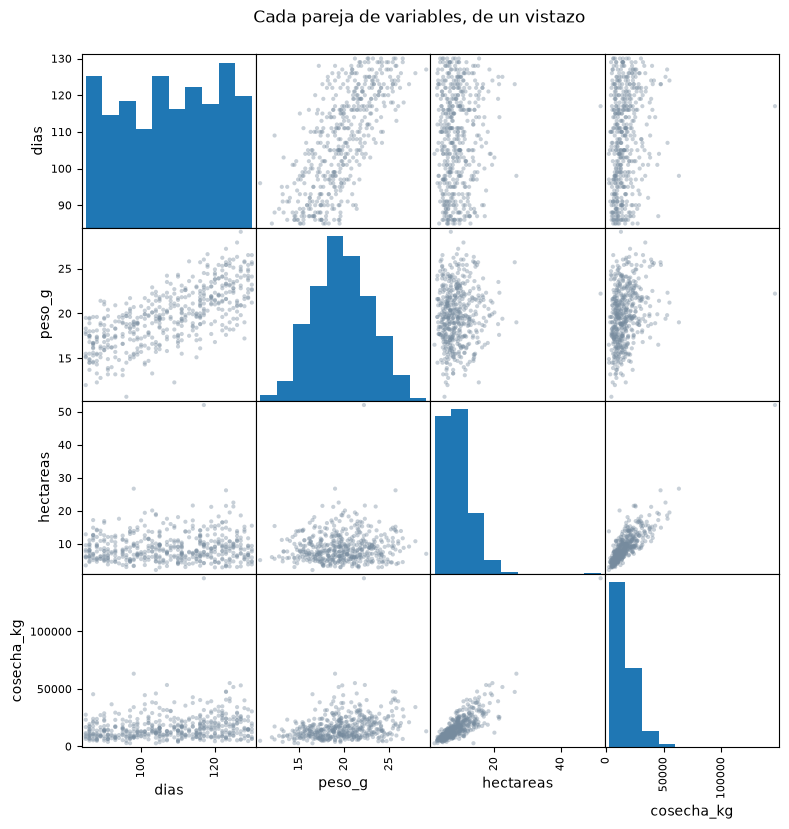

In [73]:
pd.plotting.scatter_matrix(c[["dias", "peso_g", "hectareas", "cosecha_kg"]], figsize=(9, 9), diagonal="hist", alpha=0.4, color="#768B9E")
plt.suptitle("Cada pareja de variables, de un vistazo", y=0.93)
plt.show()

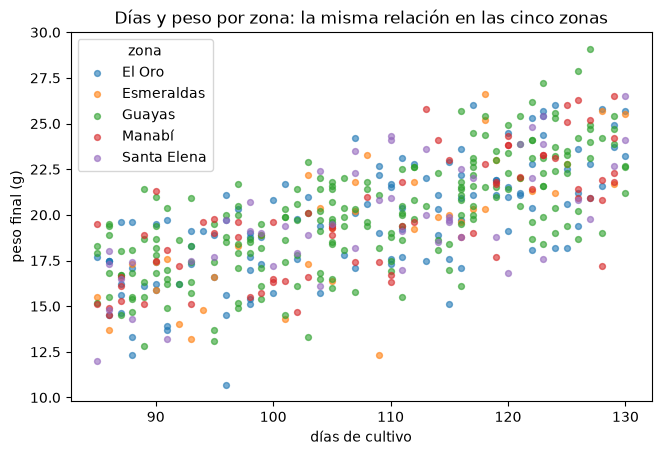

In [ ]:
# Dispersión días-peso coloreada por zona: ¿la relación es la misma en todas?
fig, ax = plt.subplots(figsize=(7.5, 4.8))

# grupo es un dataframe filtrado sólo con la zona = zona 
for zona, grupo in c.groupby("zona"):
    ax.scatter(grupo["dias"], grupo["peso_g"], alpha=0.6, s=18, label=zona)

ax.set_xlabel("días de cultivo")
ax.set_ylabel("peso final (g)")
ax.set_title("Días y peso por zona: la misma relación en las cinco zonas")
ax.legend(title="zona")
plt.show()

### Su turno 5.1 · 4 min
Repita la dispersión `dias`–`peso_g`, pero coloreada por `laboratorio` (de dónde viene la larva), con leyenda, etiquetas y título. ¿Algún laboratorio queda sistemáticamente por encima o por debajo de los demás?

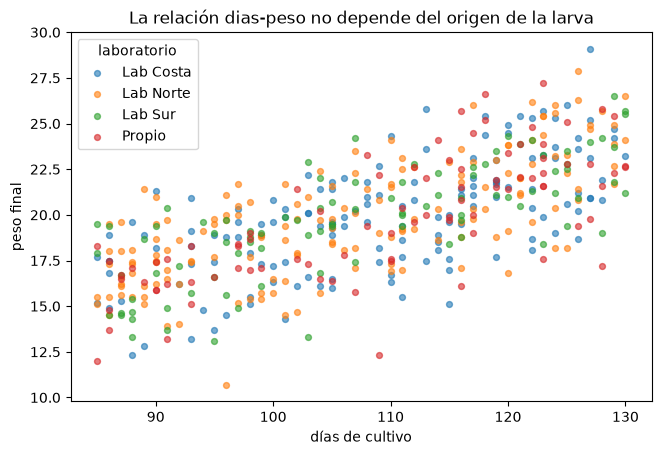

In [91]:
# TODO: reemplace los ... por su código
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for lab, grupo in c.groupby("laboratorio"):
    ax.scatter(grupo["dias"], grupo["peso_g"], alpha=0.6, s=18, label=lab)
ax.set_xlabel("días de cultivo")
ax.set_ylabel("peso final")
ax.set_title("La relación dias-peso no depende del origen de la larva")
ax.legend(title="laboratorio")
plt.show()

In [89]:
assert len(ax.collections) == 4 and ax.get_legend() is not None and len(ax.get_legend().get_texts()) == 4, "un ax.scatter por laboratorio, con label= y ax.legend()"
assert ax.get_xlabel() != "" and ax.get_ylabel() != "" and ax.get_title() != "", "faltan etiquetas o título"
print("Correcto. Los cuatro laboratorios se mezclan: la relación días-peso no depende del origen de la larva.")

Correcto. Los cuatro laboratorios se mezclan: la relación días-peso no depende del origen de la larva.


## 6. Correlación no es causalidad (y por qué el gráfico va primero)

Una correlación alta dice que dos variables **se mueven juntas**. No dice que una **cause** la otra. Tres trampas:

1. **Una tercera variable** mueve a las dos. En cosechas, `alimento_kg` y `cosecha_kg` tienen r = 0,98: no es que dar más alimento produzca más cosecha; las dos crecen con el **tamaño** de la piscina (hectáreas × densidad). Para comparar manejo entre piscinas hay que **normalizar** (por hectárea, por persona, por día).
2. **Dirección al revés**: ¿el precio sube porque el camarón es grande, o se cultiva más días porque el precio del grande es bueno? El número no lo sabe.
3. **Casualidad**: con 8 variables hay 28 parejas; con pocos datos, alguna sale correlada por azar. Una correlación «sorprendente» con pocos datos se verifica antes de contarla.

Y el gráfico va primero porque **el mismo `r` puede venir de nubes muy distintas**: el cuarteto de Anscombe (1973) son cuatro conjuntos de datos con la misma correlación (0,82), la misma media y la misma recta.

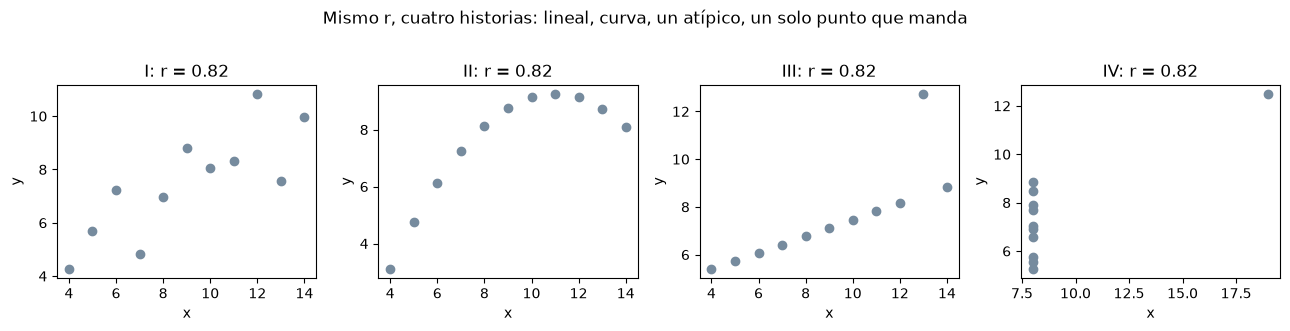

In [92]:
# El cuarteto de Anscombe: cuatro conjuntos, el mismo r = 0.82
x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = {
    "I":   (x, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  (x, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (x, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (nombre, (xa, ya)) in zip(axes, anscombe.items()):
    r = np.corrcoef(xa, ya)[0, 1]
    ax.scatter(xa, ya, color="#768B9E"); ax.set_title(f"{nombre}: r = {r:.2f}"); ax.set_xlabel("x"); ax.set_ylabel("y")
fig.suptitle("Mismo r, cuatro historias: lineal, curva, un atípico, un solo punto que manda", y=1.02)
fig.tight_layout()
plt.show()

In [93]:
# Normalizar por tamaño cambia la pregunta: densidad y cosecha, en kilos y en kilos por hectárea
c["cosecha_ha"] = c["cosecha_kg"] / c["hectareas"]
print("densidad-cosecha_kg   :", round(c["densidad"].corr(c["cosecha_kg"]), 2), " (las hectáreas esconden la relación)")
print("densidad-cosecha_ha   :", round(c["densidad"].corr(c["cosecha_ha"]), 2), " (por hectárea: sembrar más denso rinde más)")

densidad-cosecha_kg   : 0.37  (las hectáreas esconden la relación)
densidad-cosecha_ha   : 0.7  (por hectárea: sembrar más denso rinde más)


## 7. Errores frecuentes

| Síntoma | Causa | Solución |
| :-- | :-- | :-- |
| `corr()` devuelve una tabla enorme o con columnas sin sentido | se pasaron identificadores, códigos o fechas | seleccione solo las numéricas que se pueden correlacionar |
| `ValueError: could not convert string to float` en `corr()` | columnas de texto en el DataFrame | `df[columnas_numericas].corr()` o `numeric_only=True` |
| `r ≈ 0` pero el gráfico muestra una curva clara | relación no lineal | Spearman si es monótona; describa la forma con el gráfico |
| `r` muy alto «sorprendente» | un atípico lejano o dos columnas que miden lo mismo | mire la dispersión; compare con Spearman; detecte redundancias |
| se concluye «x causa y» | correlación ≠ causalidad | tercera variable, dirección, azar; normalice por tamaño |
| mapa de calor sin escala fija | `vmin`/`vmax` por defecto | `vmin=-1, vmax=1` siempre, para que el color sea comparable |
| `scatter_matrix` ilegible | demasiadas columnas | elija 4–6 columnas que importen |
| dispersión «rellena» sin forma | muchos puntos encimados | `alpha=0.3`, `s` pequeño; o agrupe (`cut`) y promedie |

## 8. Hacia el proyecto: relaciones en sus datos

La **Entrega 1** (sesión 14) pide, además de la descripción de cada variable (sesión 10), las **relaciones** que responden sus preguntas de negocio. Con lo de hoy:

| Pregunta del proyecto | Herramienta | Qué entregar |
| :-- | :-- | :-- |
| «¿x se relaciona con y?» (dos numéricas) | dispersión + Pearson y Spearman | el gráfico con etiquetas, los dos `r` y **una frase** (dirección, forma, fuerza) |
| «¿qué variables van juntas?» (tres o más numéricas) | matriz de correlación + mapa de calor | el mapa y las dos o tres parejas que importan; marcar las redundantes |
| «¿la relación cambia según el grupo?» | dispersión coloreada por una categórica | el gráfico y una frase |
| «¿x causa y?» | no se responde con correlación | diga qué tercera variable podría explicarla |

### Su turno 8.1 · en casa
Con la tabla limpia de la Tarea 1: elija **dos variables numéricas** que use alguna de sus preguntas y haga la dispersión (etiquetas con unidad), calcule Pearson y Spearman y escriba una frase con el número. Si su tabla tiene **tres o más** numéricas, añada la matriz de correlación como mapa de calor y señale las parejas redundantes. Traiga el notebook a la sesión 12.

In [ ]:
# Con su conjunto de datos (complete con sus columnas)
# datos = pd.read_csv("datos/mi_dataset_limpio.csv")
# x, y = "columna_x", "columna_y"
# fig, ax = plt.subplots(figsize=(7, 4.5)); ax.scatter(datos[x], datos[y], alpha=0.5)
# ax.set_xlabel("... (unidad)"); ax.set_ylabel("... (unidad)"); ax.set_title("...")
# print("Pearson:", round(datos[x].corr(datos[y]), 2), "| Spearman:", round(datos[x].corr(datos[y], method="spearman"), 2))
# m = datos[["col1", "col2", "col3"]].corr().round(2)   # si hay tres o más numéricas

**Antes de la próxima sesión (S12):** series de tiempo (tema 3.5): fechas como índice, `resample` y medias móviles. Traiga «Su turno 8.1». Lecturas: McKinney cap. 5 §5.3, apartado «Correlación y covarianza» (en la lectura de la sesión 10) y cap. 9 §9.2 «Trazar gráficos con pandas y seaborn» (dispersión, `scatter_matrix`); VanderPlas cap. 4, «Simple Scatter Plots» y «Visualization with Seaborn» (`pairplot`, `heatmap`).